# Import Library dan Konfigurasi

In [1]:
import os, glob, hashlib, warnings
from pathlib import Path
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt, seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display

warnings.filterwarnings('ignore')
PAL = ['#093C5D', '#3B7597', '#6FD1D7', '#5DF8D8']
INK = '#093C5D'
SPLIT_C = {'train': PAL[1], 'test': PAL[2]}
CMAP = LinearSegmentedColormap.from_list('gelar', PAL)
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.gif', '.webp', '.tif', '.tiff'}
SEED = 42

sns.set_theme(style='whitegrid', rc={
    'axes.edgecolor': INK, 'axes.labelcolor': INK, 'axes.titlecolor': INK, 'axes.titleweight': 'bold',
    'text.color': INK, 'xtick.color': INK, 'ytick.color': INK, 'grid.color': '#DCEBF0',
    'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110})


def show_grid(paths, titles=None, ncols=6, size=2.2, title=None):
    paths = list(paths); n = len(paths)
    titles = list(titles) if titles is not None else [None] * n
    nr = int(np.ceil(n / ncols))
    fig, axs = plt.subplots(nr, ncols, figsize=(ncols * size, nr * size * 1.1))
    axs = np.ravel(axs)
    for a in axs: a.axis('off')
    for a, p, t in zip(axs, paths, titles):
        try: a.imshow(Image.open(p).convert('RGB'))
        except Exception: a.text(.5, .5, 'unreadable', ha='center', va='center', transform=a.transAxes, color=INK)
        if t: a.set_title(str(t), fontsize=7)
    if title: fig.suptitle(title, fontweight='bold', color=INK)
    plt.tight_layout(rect=[0, 0, 1, .97]); plt.show()


def dist_plot(col, label, log=False, bins=40):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={'width_ratios': [2, 1]})
    sns.histplot(data=imgs, x=col, hue='split', palette=SPLIT_C, bins=bins, kde=True, element='step', log_scale=log, ax=ax[0])
    sns.boxplot(data=imgs, x='split', y=col, palette=SPLIT_C, ax=ax[1])
    if log: ax[1].set_yscale('log')
    ax[0].set_title(f'Distribusi {label}'); ax[0].set_xlabel(label)
    ax[1].set_title('Boxplot'); ax[1].set_xlabel(''); ax[1].set_ylabel(label)
    plt.tight_layout(); plt.show()


def count_plot(col, title):
    d = imgs.assign(**{col: imgs[col].astype(str)})
    fig, ax = plt.subplots(figsize=(7, 3.6))
    sns.countplot(data=d, x=col, hue='split', palette=SPLIT_C, order=d[col].value_counts().index, ax=ax)
    for c in ax.containers: ax.bar_label(c, padding=2, fontsize=8)
    ax.set_title(title); ax.set_xlabel(''); ax.set_ylabel('Jumlah')
    plt.tight_layout(); plt.show()

# EDA 
## Struktur Dataset

,split,folder,n_file,n_gambar
0,other,dsc-data-science-competition-gelar-rasa-2026,1,0
1,test,dsc-data-science-competition-gelar-rasa-2026/D...,480,480
2,train,dsc-data-science-competition-gelar-rasa-2026/D...,1920,1920


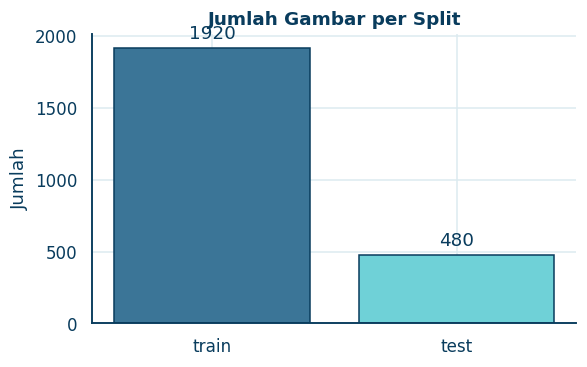

In [2]:
ROOT = Path('/kaggle/input')
files = pd.DataFrame({'path': [p for p in ROOT.rglob('*') if p.is_file()]})
rel = files.path.map(lambda p: p.relative_to(ROOT).parts[1:])
files['folder'] = rel.map(lambda t: '/'.join(t[:-1]) or '(root)')
files['split'] = rel.map(lambda t: 'train' if any(x.lower().startswith('train') for x in t[:-1])
                         else 'test' if any(x.lower().startswith('test') for x in t[:-1]) else 'other')
files['ext'] = files.path.map(lambda p: p.suffix.lower())
files['is_img'] = files.ext.isin(IMG_EXT)

imgs = files[files.is_img & files.split.isin(['train', 'test'])].copy().reset_index(drop=True)
display(files.groupby(['split', 'folder']).agg(n_file=('path', 'size'), n_gambar=('is_img', 'sum')).reset_index())

cnt = imgs.split.value_counts()
fig, ax = plt.subplots(figsize=(5.5, 3.5))
b = ax.bar(cnt.index, cnt.values, color=[SPLIT_C[s] for s in cnt.index], edgecolor=INK)
ax.bar_label(b, padding=3); ax.set_title('Jumlah Gambar per Split'); ax.set_ylabel('Jumlah')
plt.tight_layout(); plt.show()

## Metadata dan Nama File

,split,name,ext,size_kb,mtime,pattern
2037,train,1159.jpg,.jpg,45.193359,2026-10-31 07:43:44.434212208,N4
1978,train,1804.jpg,.jpg,13.063477,2026-10-31 07:43:46.286615849,N4
855,train,0789.jpg,.jpg,70.467773,2026-10-31 07:43:43.471208811,N4
1719,train,1000.jpg,.jpg,37.395508,2026-10-31 07:43:43.993686676,N4
2019,train,0593.jpg,.jpg,16.790039,2026-10-31 07:43:42.733978271,N4
134,test,412.jpg,.jpg,40.926758,2026-10-31 07:43:40.906925917,N3
1375,train,0148.jpg,.jpg,20.368164,2026-10-31 07:43:41.344960213,N4
1711,train,1645.jpg,.jpg,4.916992,2026-10-31 07:43:45.895541191,N4


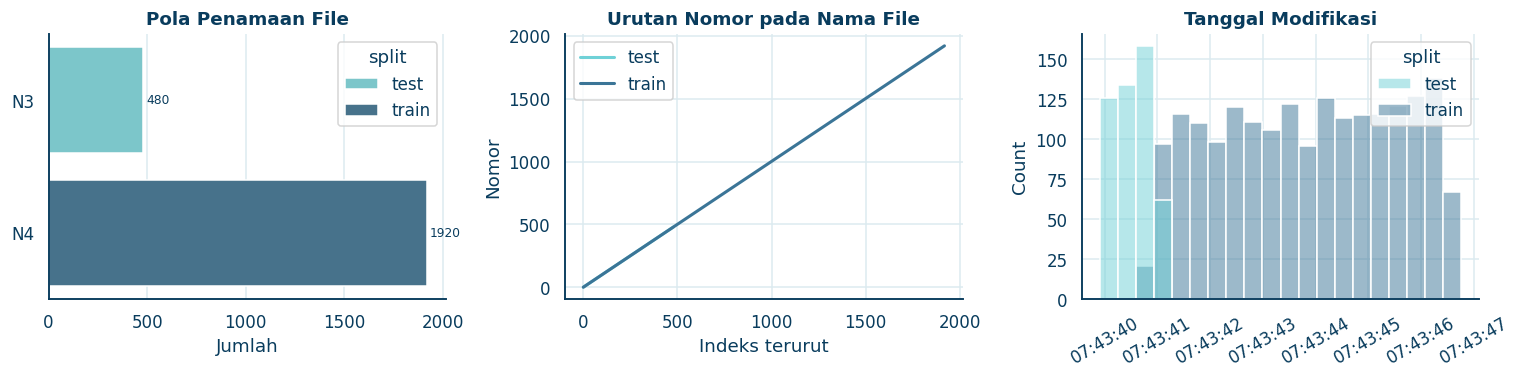

In [3]:
imgs['name'] = imgs.path.map(lambda p: p.name)
imgs['stem'] = imgs.path.map(lambda p: p.stem)
st = imgs.path.map(os.stat)
imgs['size_kb'] = st.map(lambda s: s.st_size / 1024)
imgs['mtime'] = pd.to_datetime(st.map(lambda s: s.st_mtime), unit='s')
imgs['pattern'] = (imgs.stem.str.replace(r'[A-Za-z]+', 'A', regex=True)
                   .str.replace(r'\d+', lambda m: f'N{len(m.group())}', regex=True))
imgs['num'] = pd.to_numeric(imgs.stem.str.extract(r'(\d+)')[0], errors='coerce')
display(imgs[['split', 'name', 'ext', 'size_kb', 'mtime', 'pattern']].sample(8, random_state=SEED))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
sns.countplot(data=imgs, y='pattern', hue='split', palette=SPLIT_C, ax=ax[0])
for c in ax[0].containers: ax[0].bar_label(c, padding=2, fontsize=8)
ax[0].set_title('Pola Penamaan File'); ax[0].set_ylabel(''); ax[0].set_xlabel('Jumlah')
for s, d in imgs.groupby('split'): ax[1].plot(np.sort(d.num.values), color=SPLIT_C[s], lw=2, label=s)
ax[1].set_title('Urutan Nomor pada Nama File'); ax[1].set_xlabel('Indeks terurut'); ax[1].set_ylabel('Nomor'); ax[1].legend()
sns.histplot(data=imgs, x='mtime', hue='split', palette=SPLIT_C, bins=20, ax=ax[2])
ax[2].set_title('Tanggal Modifikasi'); ax[2].set_xlabel(''); ax[2].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

## Format Gambar

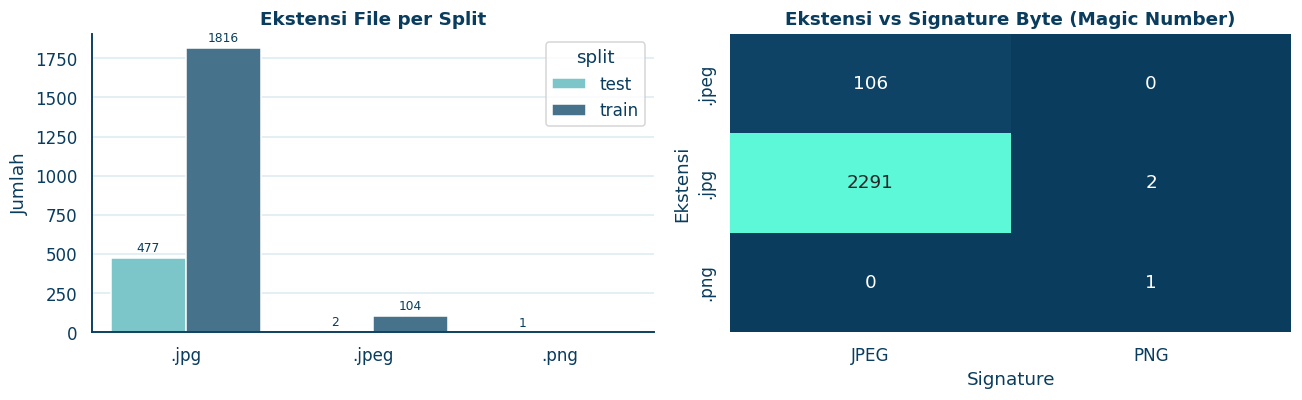

In [4]:
def sniff(p):
    with open(p, 'rb') as f: h = f.read(16)
    if h[:3] == b'\xff\xd8\xff': return 'JPEG'
    if h[:8] == b'\x89PNG\r\n\x1a\n': return 'PNG'
    if h[:4] == b'GIF8': return 'GIF'
    if h[:2] == b'BM': return 'BMP'
    if h[:4] == b'RIFF' and h[8:12] == b'WEBP': return 'WEBP'
    if h[:4] in (b'II*\x00', b'MM\x00*'): return 'TIFF'
    return 'UNKNOWN' if h else 'EMPTY'

imgs['sig'] = [sniff(p) for p in imgs.path]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sns.countplot(data=imgs, x='ext', hue='split', palette=SPLIT_C, ax=ax[0])
for c in ax[0].containers: ax[0].bar_label(c, padding=2, fontsize=8)
ax[0].set_title('Ekstensi File per Split'); ax[0].set_xlabel(''); ax[0].set_ylabel('Jumlah')
sns.heatmap(pd.crosstab(imgs.ext, imgs.sig), annot=True, fmt='d', cmap=CMAP, cbar=False, ax=ax[1])
ax[1].set_title('Ekstensi vs Signature Byte (Magic Number)'); ax[1].set_xlabel('Signature'); ax[1].set_ylabel('Ekstensi')
plt.tight_layout(); plt.show()

## Katalog Visual Gambar

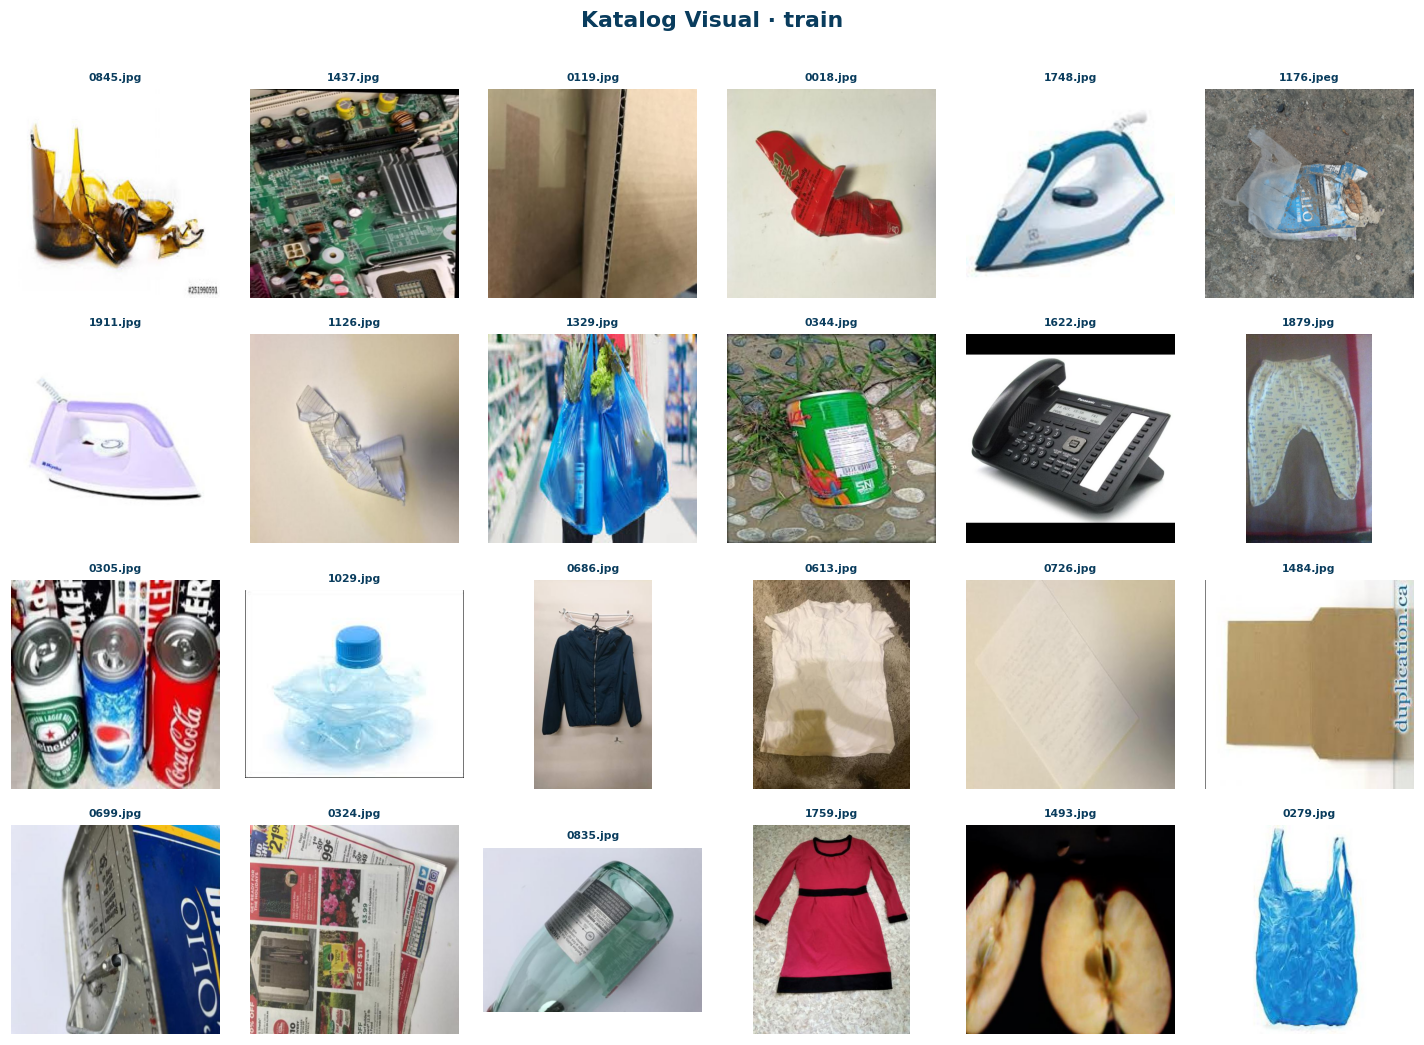

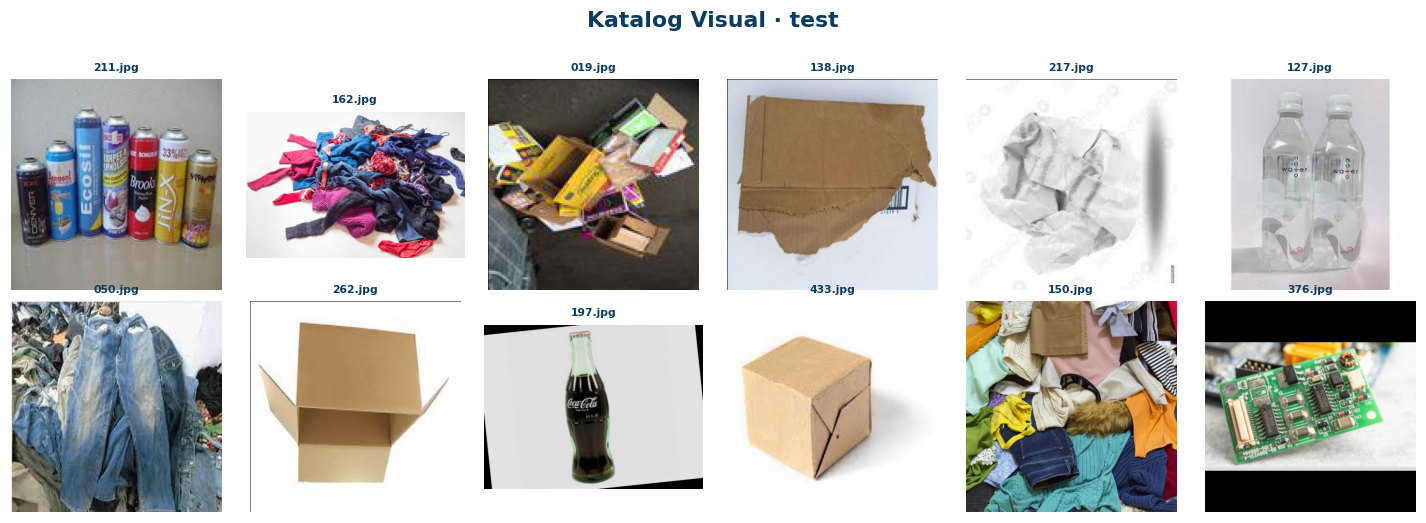

In [5]:
for s, n in [('train', 24), ('test', 12)]:
    d = imgs[imgs.split == s].sample(n, random_state=SEED)
    show_grid(d.path, d['name'], title=f'Katalog Visual · {s}')

## Dimensi Gambar dan Aspek Rasio

  0%|          | 0/2400 [00:00<?, ?it/s]

w                 h                 ar                 mp         \
       min median   max  min median   max   min median   max   min median   
split                                                                       
test   129  416.0  1600  168  416.0  1167  0.33    1.0  2.11  0.05   0.17   
train  100  509.0  2605  100  485.5  4032  0.56    1.0  2.85  0.01   0.21   

             
        max  
split        
test   1.87  
train  9.14

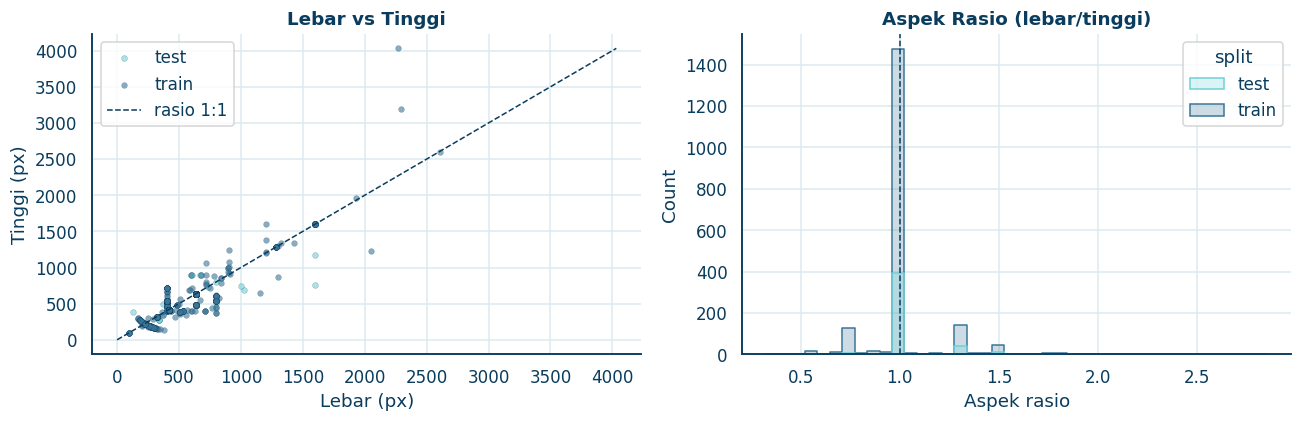

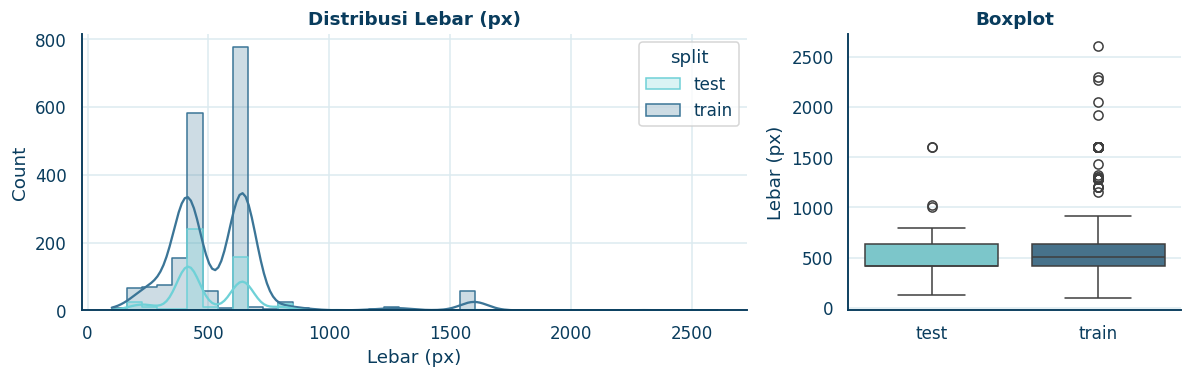

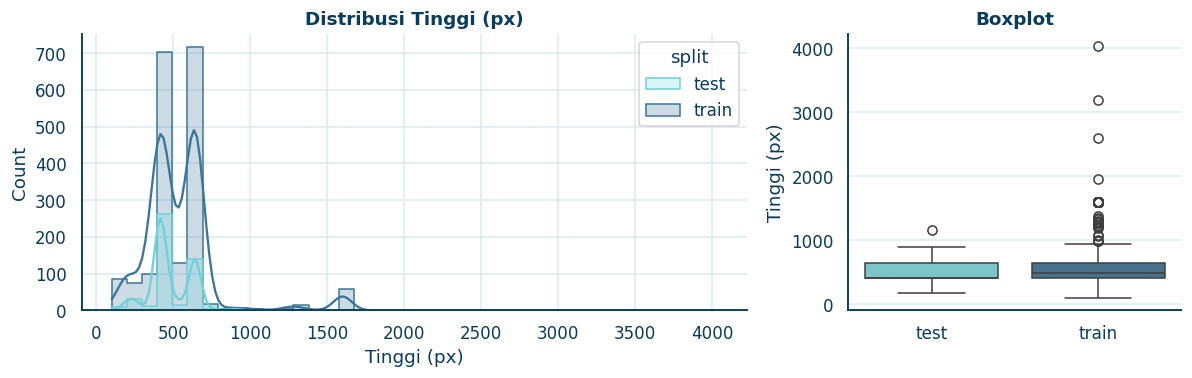

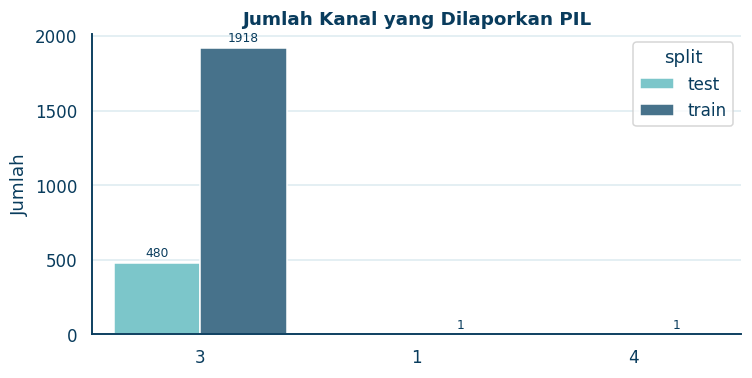

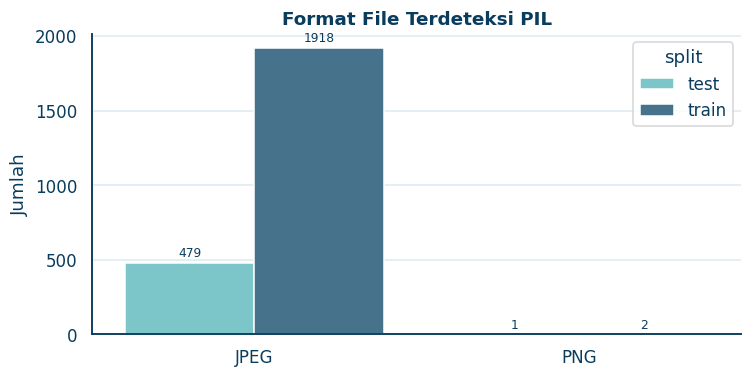

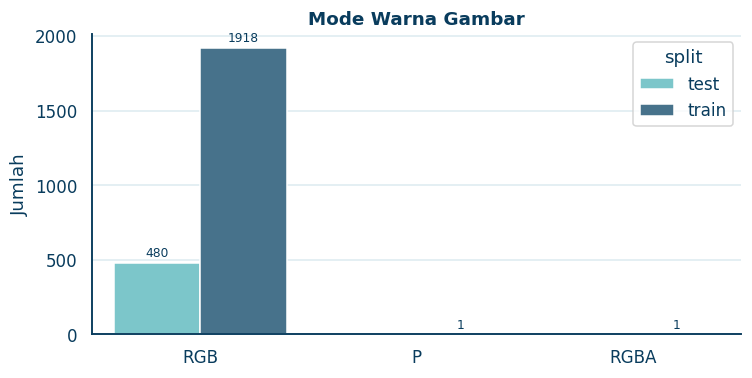

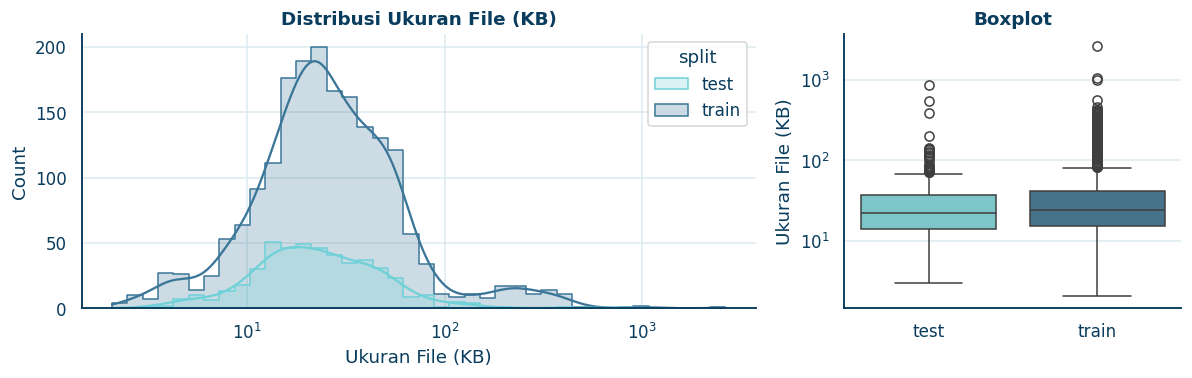

In [6]:
def meta(p):
    try:
        with Image.open(p) as im: return im.width, im.height, len(im.getbands()), im.format, im.mode
    except Exception:
        return np.nan, np.nan, np.nan, None, None

M = pd.DataFrame([meta(p) for p in tqdm(imgs.path)], columns=['w', 'h', 'n_ch', 'fmt', 'mode'], index=imgs.index)
imgs[M.columns] = M
imgs['ar'] = imgs.w / imgs.h
imgs['mp'] = imgs.w * imgs.h / 1e6
display(imgs.groupby('split')[['w', 'h', 'ar', 'mp']].agg(['min', 'median', 'max']).round(2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for s, d in imgs.groupby('split'):
    ax[0].scatter(d.w, d.h, s=14, alpha=.6, color=SPLIT_C[s], edgecolor=INK, linewidth=.2, label=s)
lim = [0, np.nanmax(imgs[['w', 'h']].values)]
ax[0].plot(lim, lim, '--', color=INK, lw=1, label='rasio 1:1')
ax[0].set_title('Lebar vs Tinggi'); ax[0].set_xlabel('Lebar (px)'); ax[0].set_ylabel('Tinggi (px)'); ax[0].legend()
sns.histplot(data=imgs, x='ar', hue='split', palette=SPLIT_C, bins=40, element='step', ax=ax[1])
ax[1].axvline(1, color=INK, ls='--', lw=1); ax[1].set_title('Aspek Rasio (lebar/tinggi)'); ax[1].set_xlabel('Aspek rasio')
plt.tight_layout(); plt.show()
dist_plot('w', 'Lebar (px)')
dist_plot('h', 'Tinggi (px)')
count_plot('n_ch', 'Jumlah Kanal yang Dilaporkan PIL')
count_plot('fmt', 'Format File Terdeteksi PIL')
count_plot('mode', 'Mode Warna Gambar')
dist_plot('size_kb', 'Ukuran File (KB)', log=True)

## Distribusi Warna dan Kecerahan

  0%|          | 0/2400 [00:00<?, ?it/s]

,r_mean,g_mean,b_mean,r_std,g_std,b_std,brightness,contrast,saturation
split,,,,,,,,,
test,162.899994,155.300003,150.199997,54.599998,54.799999,56.400002,157.000000,53.900002,49.8
train,159.199997,151.300003,143.699997,51.700001,52.500000,55.000000,152.800003,51.400002,54.5


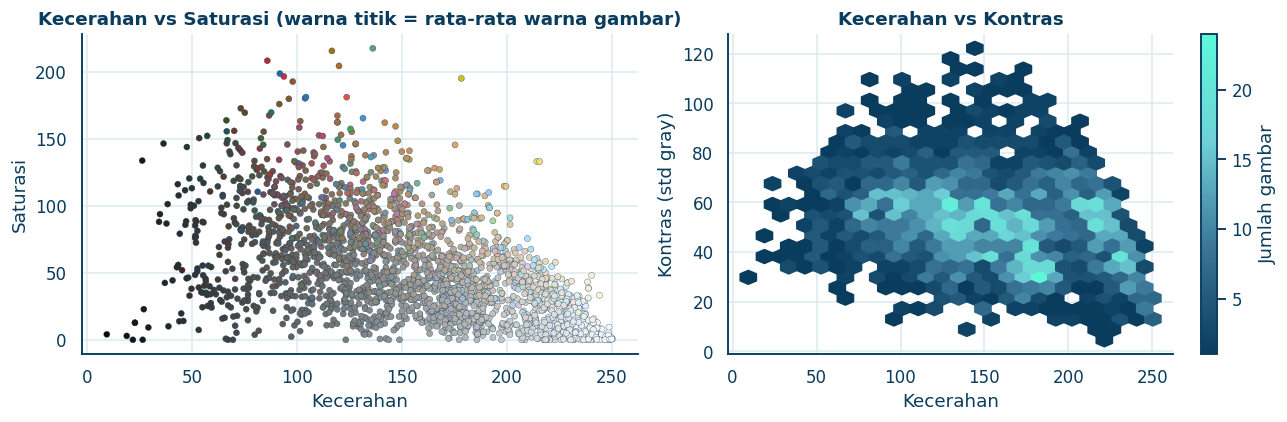

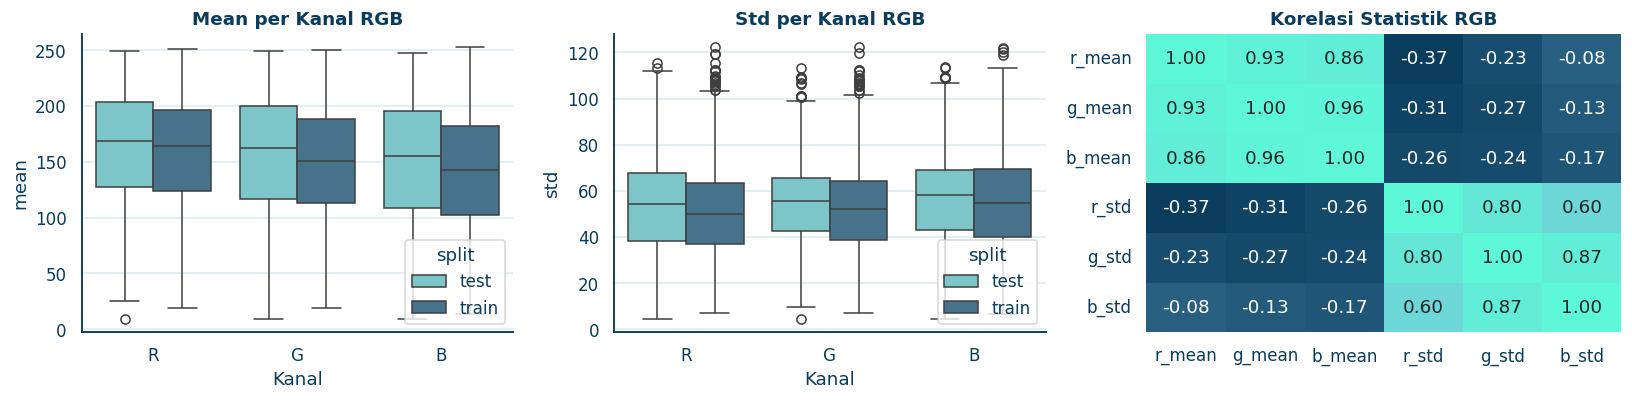

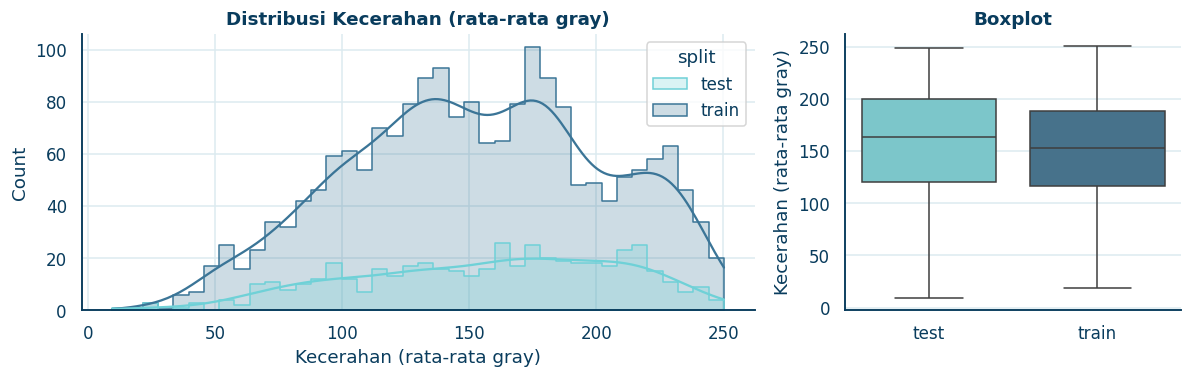

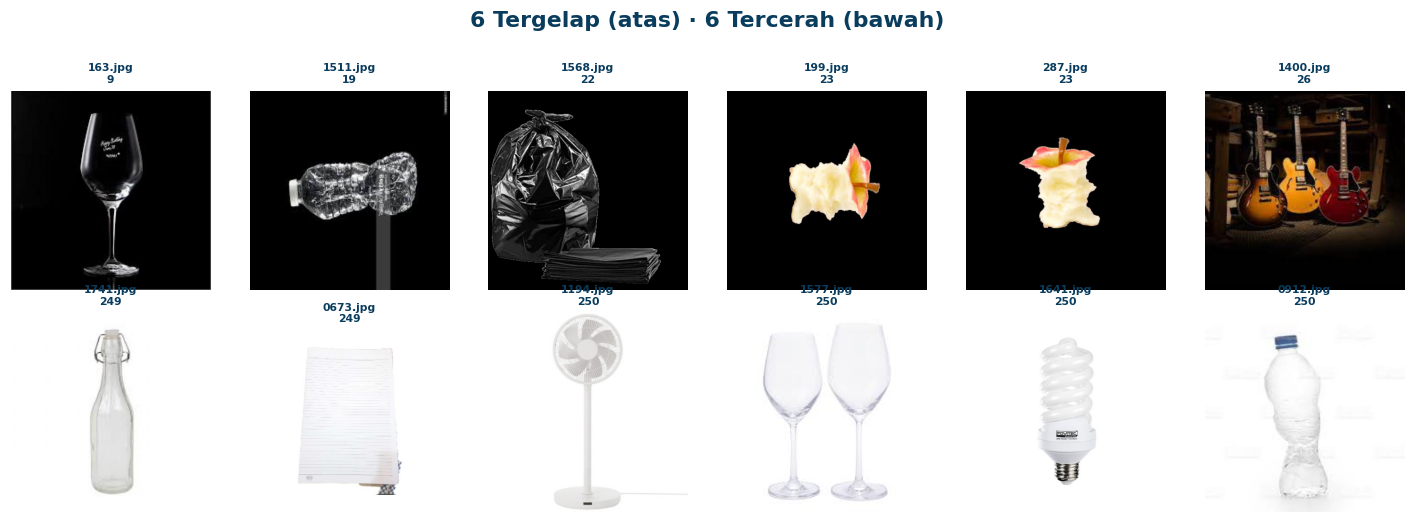

  0%|          | 0/2400 [00:00<?, ?it/s]

lap_var                           noise_sigma                \
          min      median           max         min median    max   
split                                                               
test    11.86  634.229980   8925.679688        0.09   1.14  12.37   
train    8.48  608.400024  11591.490234        0.12   1.22  15.29   

      edge_density               
               min median   max  
split                            
test           0.0   0.07  0.32  
train          0.0   0.07  0.36

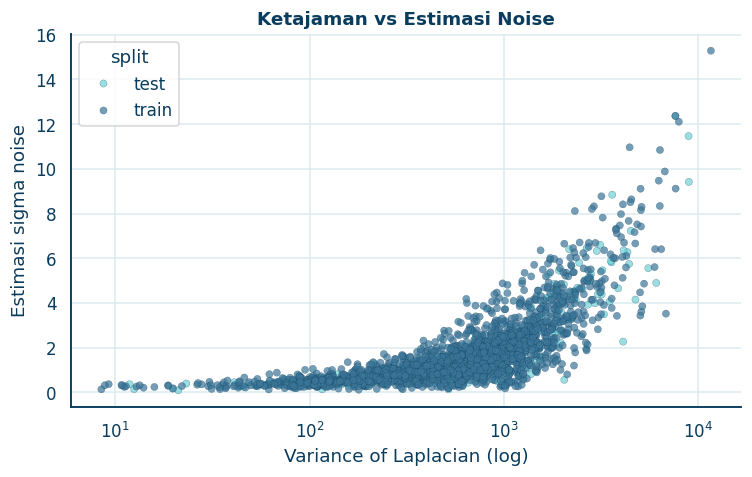

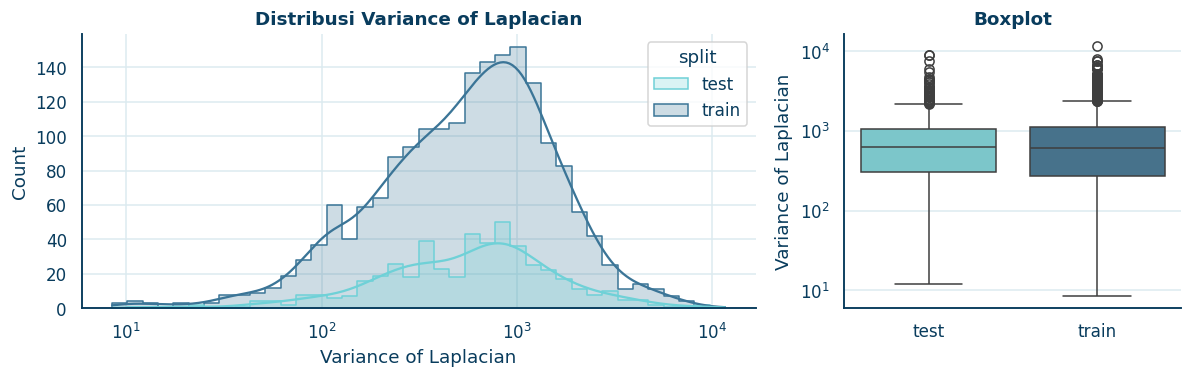

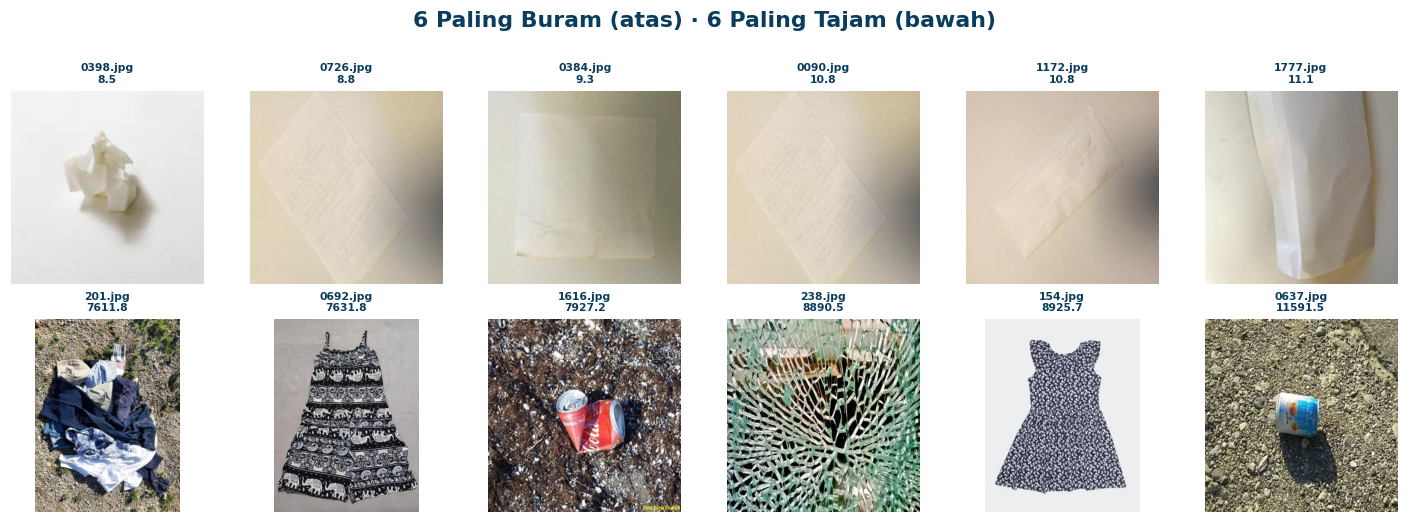

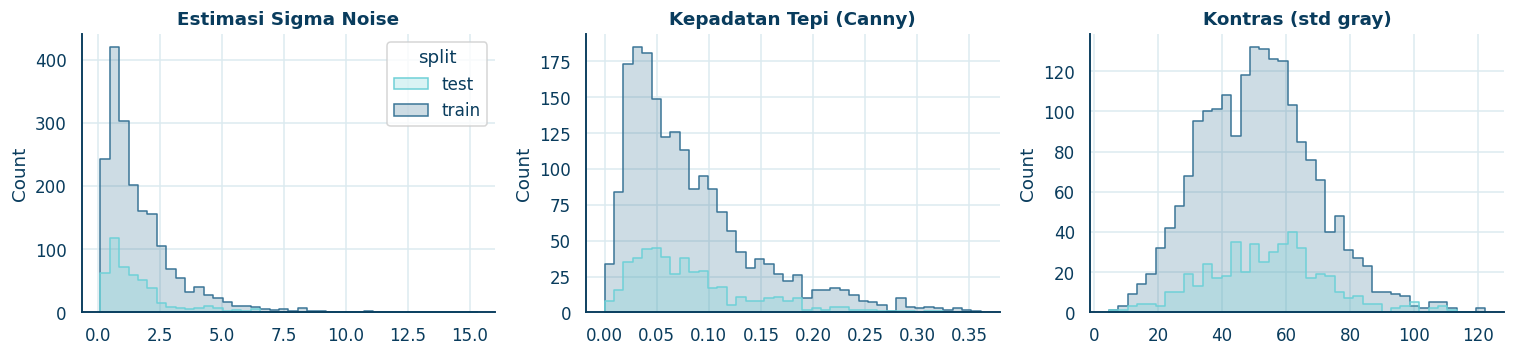

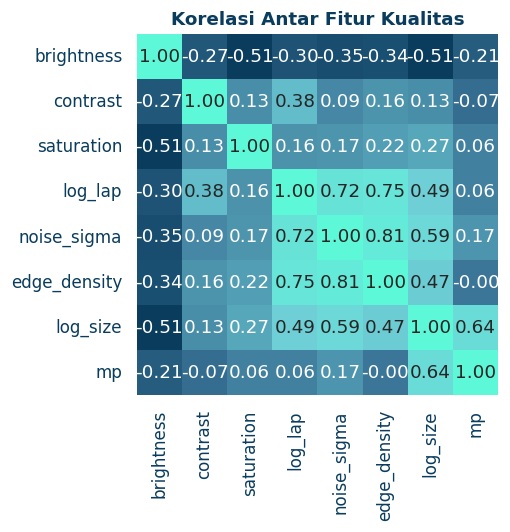

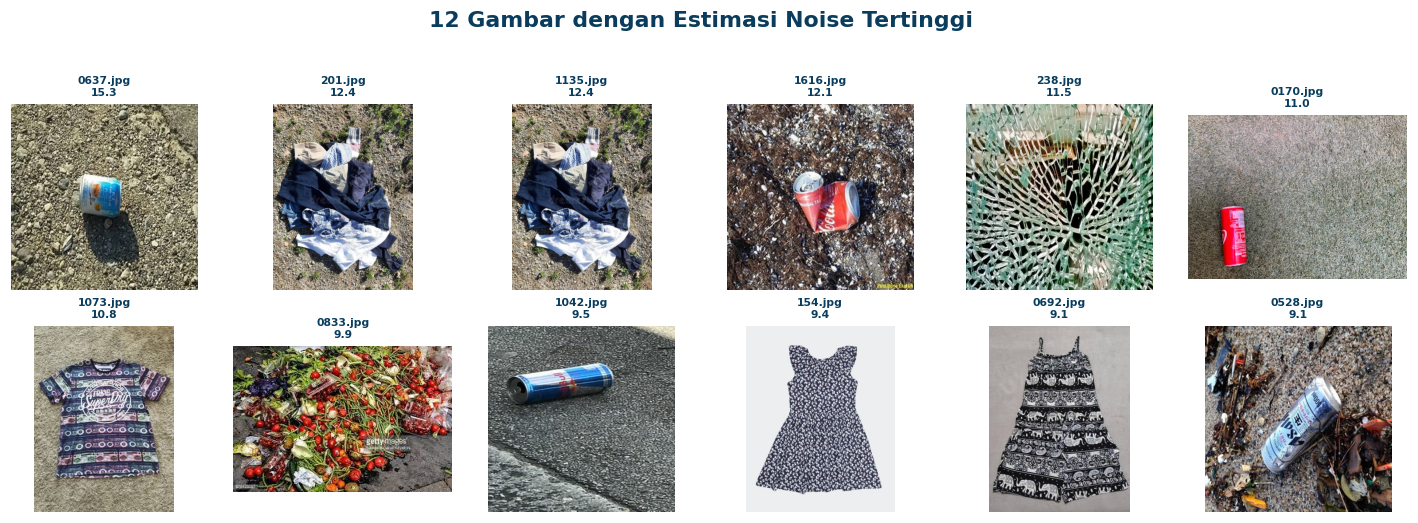

In [7]:
def color_feat(p):
    try: a = np.asarray(Image.open(p).convert('RGB').resize((128, 128)), dtype=np.float32)
    except Exception: return [np.nan] * 9
    g = a @ np.array([.299, .587, .114], dtype=np.float32)
    s = cv2.cvtColor(a.astype(np.uint8), cv2.COLOR_RGB2HSV)[..., 1].mean()
    return [*a.mean((0, 1)), *a.std((0, 1)), g.mean(), g.std(), s]

cols = ['r_mean', 'g_mean', 'b_mean', 'r_std', 'g_std', 'b_std', 'brightness', 'contrast', 'saturation']
imgs[cols] = pd.DataFrame([color_feat(p) for p in tqdm(imgs.path)], index=imgs.index, columns=cols)
display(imgs.groupby('split')[cols].mean().round(1))

rgb = np.nan_to_num(imgs[['r_mean', 'g_mean', 'b_mean']].div(255).clip(0, 1).values)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(imgs.brightness, imgs.saturation, c=rgb, s=16, edgecolor=INK, linewidth=.2)
ax[0].set_title('Kecerahan vs Saturasi (warna titik = rata-rata warna gambar)')
ax[0].set_xlabel('Kecerahan'); ax[0].set_ylabel('Saturasi')
hb = ax[1].hexbin(imgs.brightness, imgs.contrast, gridsize=25, cmap=CMAP, mincnt=1)
fig.colorbar(hb, ax=ax[1], label='Jumlah gambar')
ax[1].set_title('Kecerahan vs Kontras'); ax[1].set_xlabel('Kecerahan'); ax[1].set_ylabel('Kontras (std gray)')
plt.tight_layout(); plt.show()

# Statistik RGB
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw={'width_ratios': [1, 1, 1.1]})
for a, k in zip(ax[:2], ['mean', 'std']):
    m = imgs.melt(id_vars='split', value_vars=[f'{c}_{k}' for c in 'rgb'], var_name='ch', value_name=k)
    m['ch'] = m.ch.str[0].str.upper()
    sns.boxplot(data=m, x='ch', y=k, hue='split', palette=SPLIT_C, ax=a)
    a.set_title(f'{k.title()} per Kanal RGB'); a.set_xlabel('Kanal')
sns.heatmap(imgs[cols[:6]].corr(), annot=True, fmt='.2f', cmap=CMAP, cbar=False, ax=ax[2])
ax[2].set_title('Korelasi Statistik RGB')
plt.tight_layout(); plt.show()

#Kecerahan Gambar
dist_plot('brightness', 'Kecerahan (rata-rata gray)')
v = imgs.dropna(subset=['brightness']).sort_values('brightness')
e = pd.concat([v.head(6), v.tail(6)])
show_grid(e.path, [f"{n}\n{b:.0f}" for n, b in zip(e['name'], e.brightness)], title='6 Tergelap (atas) · 6 Tercerah (bawah)')

#Kecerhaan dan Ketajaman Gambar
K = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], np.float32)

def sharp_feat(p):
    try: g = np.asarray(Image.open(p).convert('L').resize((256, 256)), dtype=np.float32)
    except Exception: return [np.nan] * 3
    lap = cv2.Laplacian(g, cv2.CV_32F).var()
    sigma = np.sqrt(np.pi / 2) * np.abs(cv2.filter2D(g, -1, K)[1:-1, 1:-1]).sum() / (6 * 254 * 254)
    edge = cv2.Canny(g.astype(np.uint8), 100, 200).mean() / 255
    return [lap, sigma, edge]

sc = ['lap_var', 'noise_sigma', 'edge_density']
imgs[sc] = pd.DataFrame([sharp_feat(p) for p in tqdm(imgs.path)], index=imgs.index, columns=sc)
display(imgs.groupby('split')[sc].agg(['min', 'median', 'max']).round(2))

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.scatterplot(data=imgs, x='lap_var', y='noise_sigma', hue='split', palette=SPLIT_C, s=22, alpha=.7, edgecolor=INK, linewidth=.2, ax=ax)
ax.set_xscale('log'); ax.set_title('Ketajaman vs Estimasi Noise')
ax.set_xlabel('Variance of Laplacian (log)'); ax.set_ylabel('Estimasi sigma noise')
plt.tight_layout(); plt.show()

#Ketajaman Gambar pakai Lap Var
dist_plot('lap_var', 'Variance of Laplacian', log=True)
v = imgs.dropna(subset=['lap_var']).sort_values('lap_var')
e = pd.concat([v.head(6), v.tail(6)])
show_grid(e.path, [f"{n}\n{x:.1f}" for n, x in zip(e['name'], e.lap_var)], title='6 Paling Buram (atas) · 6 Paling Tajam (bawah)')

#Pemeriksaan Lainnya
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
for a, (c, t) in zip(ax, [('noise_sigma', 'Estimasi Sigma Noise'), ('edge_density', 'Kepadatan Tepi (Canny)'), ('contrast', 'Kontras (std gray)')]):
    sns.histplot(data=imgs, x=c, hue='split', palette=SPLIT_C, bins=40, element='step', ax=a, legend=a is ax[0])
    a.set_title(t); a.set_xlabel('')
plt.tight_layout(); plt.show()

F = imgs.assign(log_lap=np.log1p(imgs.lap_var), log_size=np.log1p(imgs.size_kb))[
    ['brightness', 'contrast', 'saturation', 'log_lap', 'noise_sigma', 'edge_density', 'log_size', 'mp']]
plt.figure(figsize=(6.5, 5))
sns.heatmap(F.corr(), annot=True, fmt='.2f', cmap=CMAP, square=True, cbar=False)
plt.title('Korelasi Antar Fitur Kualitas'); plt.tight_layout(); plt.show()

v = imgs.dropna(subset=['noise_sigma']).nlargest(12, 'noise_sigma')
show_grid(v.path, [f"{n}\n{x:.1f}" for n, x in zip(v['name'], v.noise_sigma)], title='12 Gambar dengan Estimasi Noise Tertinggi')

## Kualitas dan Kondisi Gambar

  0%|          | 0/2400 [00:00<?, ?it/s]

split,test,train
corrupt,0,0
truncated,0,0
cv2_unreadable,0,0
empty_file,0,0
ext_mismatch,0,2
non_rgb,0,2
tiny,0,0
extreme_ar,1,0
flat_image,1,0
too_dark,4,5


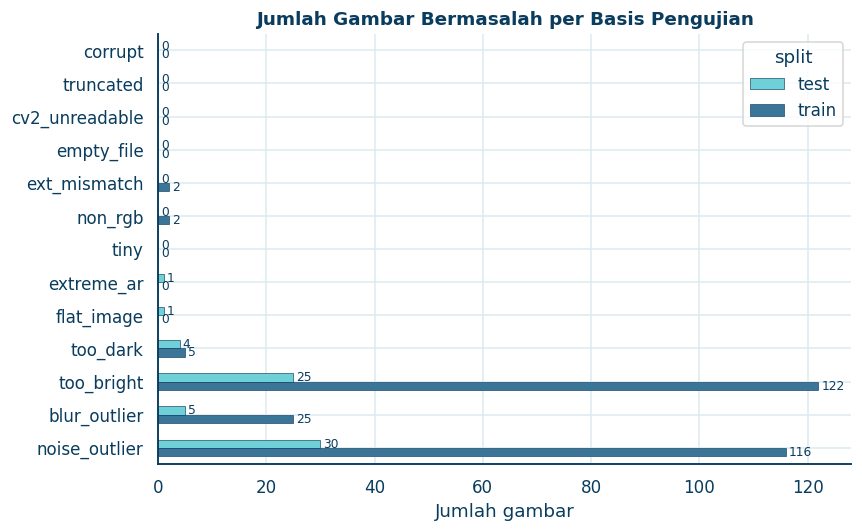

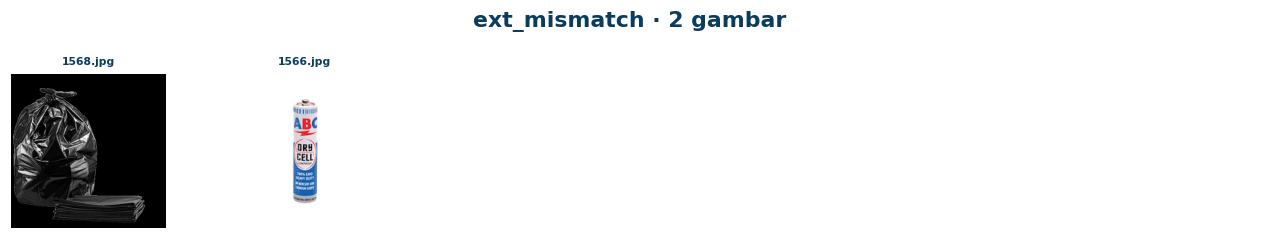

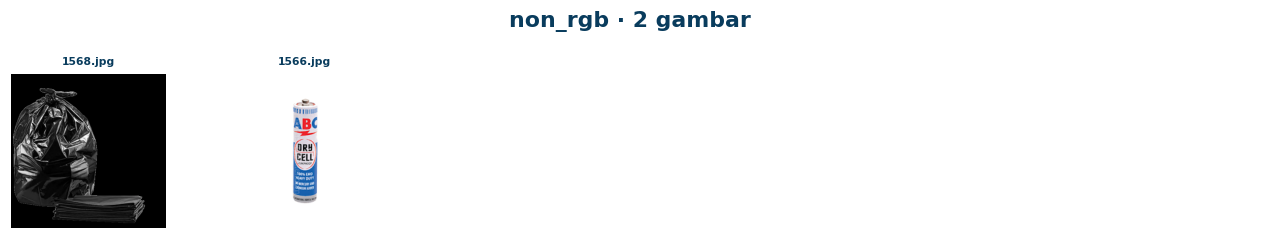

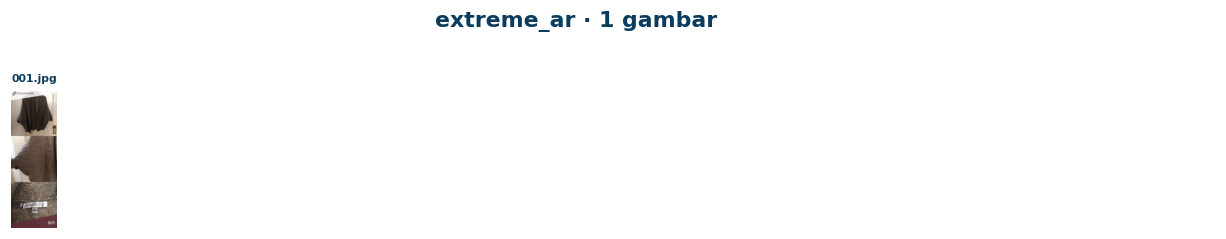

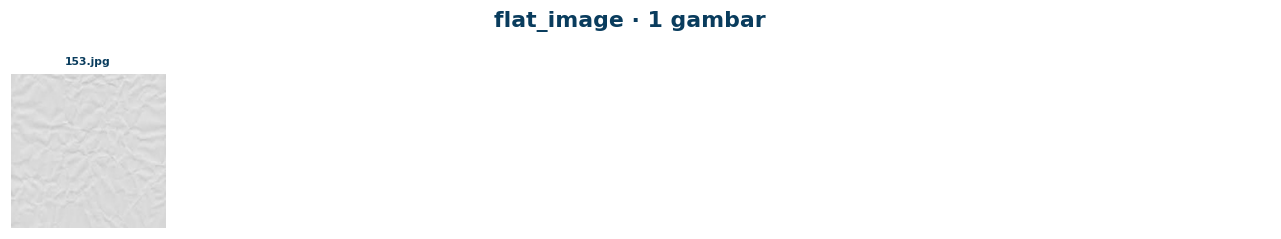

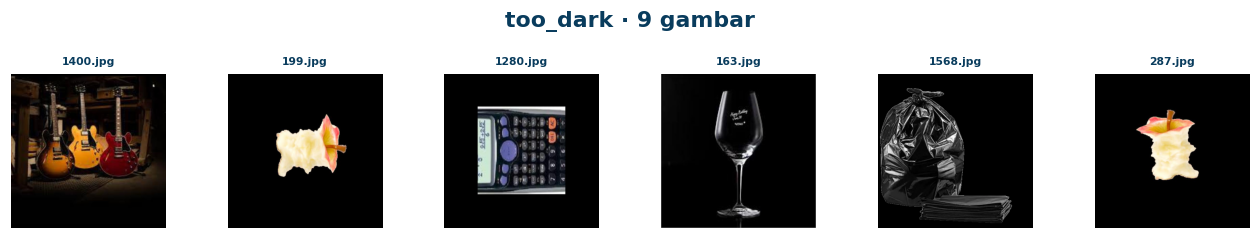

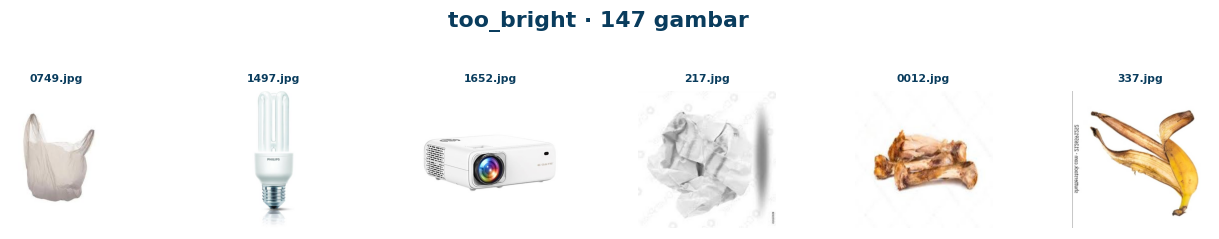

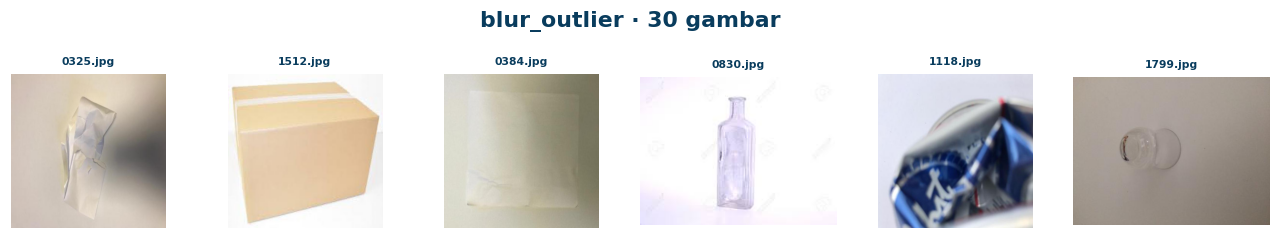

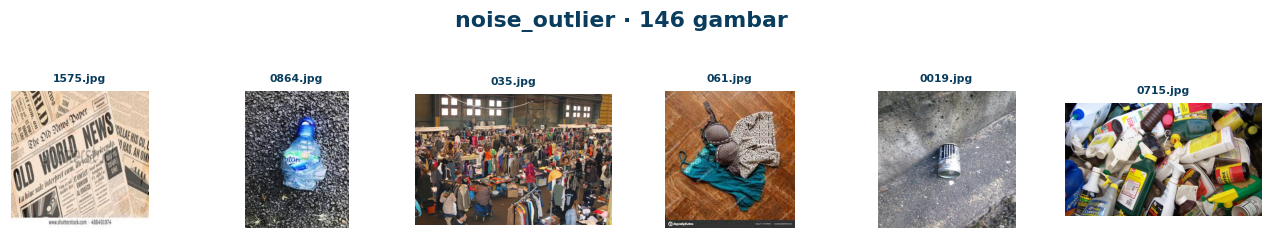

In [8]:
EXT2FMT = {'.jpg': 'JPEG', '.jpeg': 'JPEG', '.png': 'PNG', '.bmp': 'BMP', '.gif': 'GIF', '.webp': 'WEBP', '.tif': 'TIFF', '.tiff': 'TIFF'}

def check(p):
    r = [False, False, False]
    try:
        with Image.open(p) as im: im.verify()
    except Exception: r[0] = True; return r
    try:
        with Image.open(p) as im: im.load()
    except Exception: r[1] = True
    try: r[2] = cv2.imdecode(np.fromfile(p, np.uint8), cv2.IMREAD_COLOR) is None
    except Exception: r[2] = True
    return r

def fence(s, k=1.5):
    q1, q3 = s.quantile([.25, .75]); return q1 - k * (q3 - q1), q3 + k * (q3 - q1)

chk = pd.DataFrame([check(p) for p in tqdm(imgs.path)], columns=['corrupt', 'truncated', 'cv2_unreadable'], index=imgs.index)
lo_lap, _ = fence(np.log1p(imgs.lap_var)); _, hi_noise = fence(imgs.noise_sigma)
fmt_ext = imgs.ext.map(EXT2FMT)
Q = chk.assign(
    empty_file=imgs.size_kb.eq(0),
    ext_mismatch=(imgs.sig != fmt_ext) | (imgs.fmt != fmt_ext),
    non_rgb=imgs['mode'].ne('RGB'),
    tiny=imgs[['w', 'h']].min(axis=1) < 64,
    extreme_ar=~imgs.ar.between(1 / 3, 3),
    flat_image=imgs.contrast < 5,
    too_dark=imgs.brightness < 30,
    too_bright=imgs.brightness > 230,
    blur_outlier=np.log1p(imgs.lap_var) < lo_lap,
    noise_outlier=imgs.noise_sigma > hi_noise)

S = Q.groupby(imgs.split).sum().T
display(S)
ax = S.plot.barh(figsize=(8, 5), color=[SPLIT_C[c] for c in S.columns], edgecolor=INK, linewidth=.4)
for c in ax.containers: ax.bar_label(c, padding=2, fontsize=8)
ax.invert_yaxis(); ax.set_title('Jumlah Gambar Bermasalah per Basis Pengujian'); ax.set_xlabel('Jumlah gambar')
plt.tight_layout(); plt.show()

# Sampel Gambar
for k in Q.columns[Q.any()]:
    d = imgs[Q[k]].sample(min(6, int(Q[k].sum())), random_state=SEED)
    show_grid(d.path, d['name'], size=2, title=f'{k} · {int(Q[k].sum())} gambar')

## Duplikasi

  0%|          | 0/2400 [00:00<?, ?it/s]

  0%|          | 0/2400 [00:00<?, ?it/s]

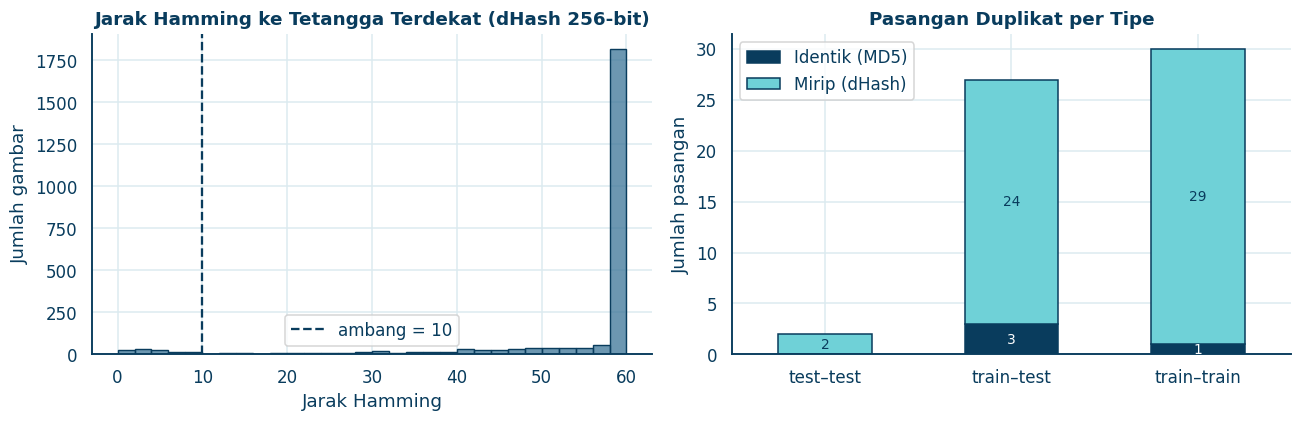

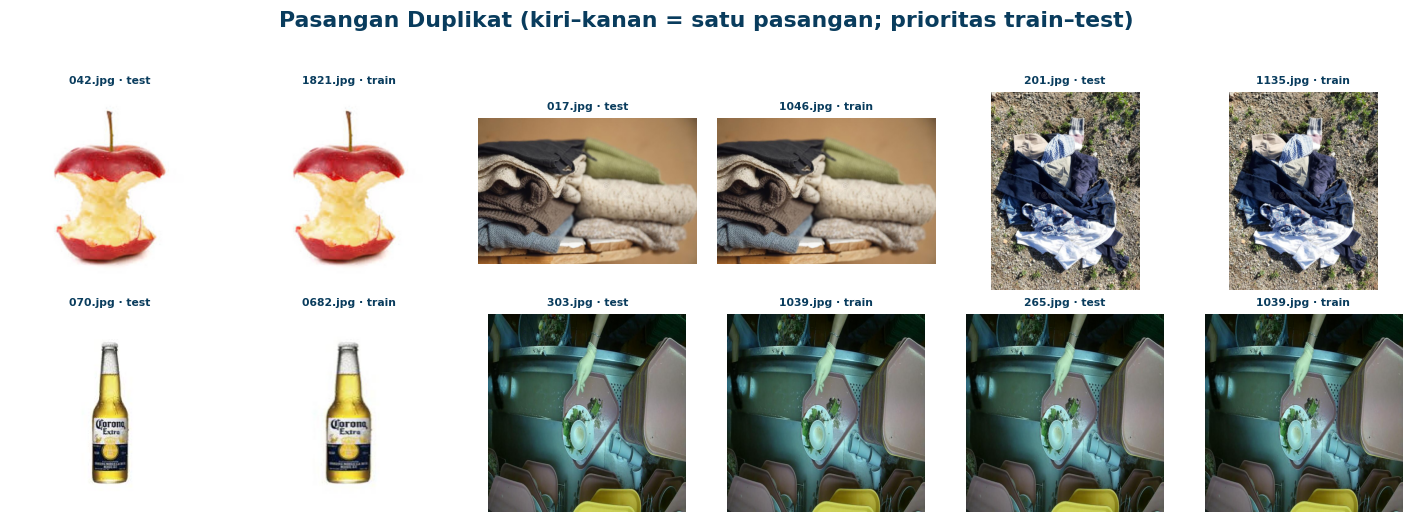

In [9]:
THR = 10
imgs['md5'] = [hashlib.md5(p.read_bytes()).hexdigest() for p in tqdm(imgs.path)]

def dhash(p, s=16):
    try: g = np.asarray(Image.open(p).convert('L').resize((s + 1, s)), dtype=np.int16)
    except Exception: return np.zeros(s * s, np.uint8)
    return (g[:, 1:] > g[:, :-1]).ravel().astype(np.uint8)

H = np.stack([dhash(p) for p in tqdm(imgs.path)]).astype(np.float32)
D = H.shape[1] - H @ H.T - (1 - H) @ (1 - H).T
I, J = np.where(np.triu(D <= THR, 1))
P = pd.DataFrame({'a': I, 'b': J, 'dist': D[I, J]})
P['exact'] = imgs.md5.values[I] == imgs.md5.values[J]
P['tipe'] = ['–'.join(sorted(x, reverse=True)) for x in zip(imgs.split.values[I], imgs.split.values[J])]
nn = np.where(np.eye(len(D), dtype=bool), np.inf, D).min(1)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(np.clip(nn, 0, 60), bins=30, color=PAL[1], edgecolor=INK, ax=ax[0])
ax[0].axvline(THR, color=PAL[0], ls='--', lw=1.5, label=f'ambang = {THR}'); ax[0].legend()
ax[0].set_title('Jarak Hamming ke Tetangga Terdekat (dHash 256-bit)'); ax[0].set_xlabel('Jarak Hamming'); ax[0].set_ylabel('Jumlah gambar')
if len(P):
    T = P.groupby(['tipe', 'exact']).size().unstack(fill_value=0).reindex(columns=[True, False], fill_value=0)
    T.plot.bar(ax=ax[1], stacked=True, color=[PAL[0], PAL[2]], rot=0, edgecolor=INK)
    ax[1].legend(['Identik (MD5)', 'Mirip (dHash)'])
    for c, tc in zip(ax[1].containers, ['white', INK]):
        ax[1].bar_label(c, labels=[str(int(v)) if v else '' for v in c.datavalues], label_type='center', color=tc, fontsize=9)
else:
    ax[1].text(.5, .5, 'Tidak ada pasangan duplikat', ha='center', va='center', transform=ax[1].transAxes)
ax[1].set_title('Pasangan Duplikat per Tipe'); ax[1].set_xlabel(''); ax[1].set_ylabel('Jumlah pasangan')
plt.tight_layout(); plt.show()

# Sampel
S = P.assign(x=P.tipe.eq('train–test')).sort_values(['x', 'exact', 'dist'], ascending=[False, False, True]).head(6)
if len(S):
    idx = [i for a, b in zip(S.a, S.b) for i in (a, b)]
    show_grid(imgs.path.values[idx], [f"{imgs['name'].values[i]} · {imgs.split.values[i]}" for i in idx],
              title='Pasangan Duplikat (kiri–kanan = satu pasangan; prioritas train–test)')